# DATA 298A Team 6 — Data pipeline

**Neurosymbolic verification of LLM-generated clinical discharge and treatment plans.**
Team 6, Section 22, Topic 12. Ritika Mukesh Neema, Rajesh Paruchuri, Akashkumar Senthilkumar, Sneha Singh, Shruthi Thirukumaran.

This notebook prepares the cases the rest of the project will use. Run the cells from top to bottom. It does not train a model and it does not run the checker. It fixes the data those pieces will share: one cleaned table set, one split, and a record of what was changed.

Patient files stay in `~/data/mimic`. The notebook writes only aggregate figures under `results/`. Clear the cell outputs before sharing the file.

| Section | What it shows |
|---|---|
| 1. Data extraction | sources, collection steps, load, representative samples |
| 2. Data cleaning | duplicates, missing values, formatting, transformations, outliers, validation |
| 3. Exploratory data analysis | statistics, plots, findings |
| 4. Splits | stratified train / validation / test and a leakage check |


## What the project is checking

Language models can already draft a discharge or treatment plan that reads like a clinician wrote it. The failure mode this project cares about is a plan that still reads well when it is unsafe: a patient sent home before a required lab is back, or a medication that the record contraindicates. Care teams catch that by reading the plan, which is late. The project builds a checker that runs first.

The checker does not ask the same model whether its own plan is fine. It turns the plan into logic and tests it against rules the team writes. A solver (Z3) either accepts the plan or names the rule that failed, so a repair can target that rule. The model never grades itself against constraints it invented.

Four models are planned. Only Model A is built in DATA 298A.

| Model | What it does | When |
|---|---|---|
| A | Generates a plan directly from the case | 298A |
| B | Translates the note and the goal into a formal specification | 298B |
| C | Adds the solver, names the broken rule, and sends it back for repair | 298B |
| D | Pairs the model with a classical PDDL planner | 298B |

The published baseline is separate from those four. It is Hager et al., *Nature Medicine* (2024), Figure 3: 54.9% diagnostic accuracy for the best open model on this benchmark's autonomous clinical decision-making task, across the same 2,400 cases. Success for the checker, on 100 held-out cases, is plan validity at or above 0.85 against the rule set, and a constraint-violation escape rate at or below 0.05.

## What the papers change in this design

Three results decide how this project is built. This notebook only prepares the 2,400 cases those results are tested on. The paper copies are in `documents/papers/`.

1. **A model can know medicine and still make an unsafe decision.** Med-PaLM (Singhal et al., 2023) scores well on exam-style questions. Hager et al. (2024) show that on these same 2,400 admissions the decision can still be wrong. Figure 3, 54.9%, is the baseline we reproduce later. It is not one of the four models.
2. **The model must not grade its own plan.** PlanBench and the self-critique results (Valmeekam et al., 2023) and Huang et al. (2024) find that asking the model "is this correct?" does not match an outside check. Kambhampati et al. (2024) keep the model as the proposer and put a separate verifier next to it. Reflexion (Shinn et al., 2023) and Olausson et al. (2024) only help when that outside signal exists. Here the signal is the rule checker.
3. **The checker is a solver, not another prompt.** LLM+P (Liu et al., 2023), Logic-LM (Pan et al., 2023), SatLM (Ye et al., 2023), and Guan et al. (2023) have the model write the problem and a planner or SAT/SMT solver decide it. Hekmatnejad et al. (2019) already used SMT on clinical decision-support rules. A failed discharge rule is named by Z3.


## What the dataset contains

Two downloads sit in `~/data/mimic`. Only one of them is the working set.

**MIMIC-IV-Ext-CDM v1.1** (Hager et al., 2024) is about 18 MB and has 2,400 hospital admissions. Every admission is labeled with one of four abdominal pathologies: appendicitis (957), cholecystitis (648), pancreatitis (538), and diverticulitis (257). That imbalance is why the split in section 4 is stratified, and why a single overall accuracy number would hide the smallest class.

Each case can include:

| Table | What it is | How a later rule would use it |
|---|---|---|
| `history_of_present_illness`, `physical_examination` | The admission note. One row per case. | The text a generated plan is conditioned on. |
| `discharge_diagnosis`, `discharge_procedures` | What was recorded at discharge. | The kind of plan the model is asked to produce. |
| `icd_diagnosis`, `icd_procedures` | Coded diagnoses and procedures. Several rows per case. | Structured facts a rule can match without rereading the note. |
| `laboratory_tests` | Lab result, as text, plus the reference range when the source had one. | Numeric checks such as low, normal, or high. |
| `microbiology` | Culture and specimen results. Present for about 77% of cases. | A rule that needs a culture has no input on the other cases. |
| `radiology_reports` | Modality, region, exam name, and the report text. | Imaging findings tied to the same admission. |
| `lab_test_mapping` | `itemid` to a readable lab name. | So a lab row is not just a number. |
| `pathology_ids.json` | The 2,400 ids grouped by pathology. | The label for the stratified split. |

**MIMIC-IV v3.1** is the full hospital database, about 10 GB on this machine. Ext-CDM is an extract of it. This notebook does not load those tables. It reads one column, `hadm_id`, from `admissions.csv.gz`, and checks that all 2,400 extract ids are real admissions. Medication orders and the timestamps of labs versus discharge are not in the 18 MB extract. A later rule that needs them would open that MIMIC-IV table at that point, not here.

The licence on both is the PhysioNet Credentialed Health Data License 1.5.0. Access is per person. The files are not in this folder, and note text is not sent to a hosted model.

## Data setup and reload

Run this cell first. It sets the project path, loads the pipeline code, and points at the data in `~/data/mimic`. Run it again after any change to the code before you continue.


In [ ]:
from pathlib import Path
import hashlib
import sys

import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from clinverify.data import ext_cdm as E
from clinverify.data import splits as S

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 120)
pd.set_option("display.expand_frame_repr", False)
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.grid"] = False

FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(1 << 20), b""):
            h.update(block)
    return h.hexdigest()

def dir_bytes(path):
    return sum(f.stat().st_size for f in path.rglob("*") if f.is_file())

def preview(df, n=3, width=60):
    """Show a few rows. Long text is cut so a sample fits on one line."""
    sample = df.head(n).copy()
    for col in sample.columns:
        if sample[col].dtype == object:
            sample[col] = (
                sample[col].astype(str).str.replace(r"\s+", " ", regex=True).str.slice(0, width)
            )
    return sample

print("project root:", ROOT)
print("Ext-CDM     :", E.EXT_CDM_DIR)
print("MIMIC-IV    :", E.MIMIC_IV_DIR, "(link check only)")


## 1. Data extraction

This section shows where the 2,400 cases came from and that the files on disk match the download. The counts below are the benchmark Hager et al. (2024) evaluate.

### 1.1 Sources

Both datasets are under `~/data/mimic`. Access is per person (CITI training and a PhysioNet data-use agreement). The files are not copied into this project.


In [2]:
sources = pd.DataFrame([
    {
        "dataset": "MIMIC-IV-Ext-CDM",
        "version": "1.1",
        "role": "working set: clean, transform, EDA, splits",
        "path": str(E.EXT_CDM_DIR),
        "on_disk": E.EXT_CDM_DIR.exists(),
        "size_mb": round(dir_bytes(E.EXT_CDM_DIR) / 1e6, 1),
        "licence": "PhysioNet Credentialed Health Data License 1.5.0",
    },
    {
        "dataset": "MIMIC-IV",
        "version": "3.1",
        "role": "parent source: admissions link check only",
        "path": str(E.MIMIC_IV_DIR),
        "on_disk": E.MIMIC_IV_DIR.exists(),
        "size_mb": round(dir_bytes(E.MIMIC_IV_DIR) / 1e6, 1),
        "licence": "PhysioNet Credentialed Health Data License 1.5.0",
    },
])
sources


,dataset,version,role,path,on_disk,size_mb,licence
0,MIMIC-IV-Ext-CDM,1.1,"working set: clean, transform, EDA, splits",~/data/mimic/mimic-iv-ext-cdm-1.1,True,18.0,PhysioNet Credentialed Health Data License 1.5.0
1,MIMIC-IV,3.1,parent source: admissions link check only,~/data/mimic/physionet.org/files/mimiciv/3.1,True,10656.2,PhysioNet Credentialed Health Data License 1.5.0


### 1.2 Collection steps

1. Each person completes CITI training and receives PhysioNet credentialed access.
2. Each person signs the data-use agreement on the MIMIC-IV page and the Ext-CDM page. The files are not shared inside the team.
3. Download into `~/data/mimic` (change the location with `MIMIC_DIR`).
4. Check Ext-CDM against the `SHA256SUMS.txt` shipped with the download. MIMIC-IV was checked once when it was downloaded (33 of 33 files). It is not hashed again here.
5. Confirm every Ext-CDM `hadm_id` is present in MIMIC-IV `admissions`.
6. Load the Ext-CDM tables into the pipeline. Leave the rest of the 9.9 GB folder untouched.


In [3]:
listed = [
    ln.split()
    for ln in (E.EXT_CDM_DIR / "SHA256SUMS.txt").read_text().replace("\r", "").splitlines()
    if len(ln.split()) == 2
]
bad = [rel for digest, rel in listed if sha256(E.EXT_CDM_DIR / rel) != digest]
n_cases = len(E.case_table(E.load_pathology_ids()))
admissions = pd.read_csv(E.MIMIC_IV_DIR / "hosp" / "admissions.csv.gz", usecols=["hadm_id"])
linked = int(E.case_table(E.load_pathology_ids())["hadm_id"].isin(admissions["hadm_id"]).sum())

collection = pd.DataFrame([
    ["Licence file present", (E.EXT_CDM_DIR / "LICENSE.txt").exists(), "Ext-CDM LICENSE.txt"],
    ["Ext-CDM checksum", f"{len(listed) - len(bad)} of {len(listed)} files match", "SHA256SUMS.txt"],
    ["Ext-CDM cases", n_cases, "pathology_ids.json"],
    ["Link check", f"{linked} of {n_cases} hadm_id found in admissions", "one column of admissions.csv.gz"],
    ["MIMIC-IV re-hashed this run", False, "already verified at download; not loaded"],
], columns=["step", "result", "evidence"])
collection


,step,result,evidence
0,Licence file present,True,Ext-CDM LICENSE.txt
1,Ext-CDM checksum,12 of 12 files match,SHA256SUMS.txt
2,Ext-CDM cases,2400,pathology_ids.json
3,Link check,2400 of 2400 hadm_id found in admissions,one column of admissions.csv.gz
4,MIMIC-IV re-hashed this run,False,already verified at download; not loaded


### 1.3 Load into the pipeline

Each Ext-CDM table is read from disk. This is the upload step: the files enter the pipeline here, and only here.


In [4]:
tables = E.load_tables()
ids = E.load_pathology_ids()
cases = E.case_table(ids)

rows = []
for name, df in tables.items():
    path = E.EXT_CDM_DIR / f"{name}.csv"
    rows.append({
        "table": name,
        "file_mb": round(path.stat().st_size / 1e6, 2),
        "rows": len(df),
        "columns": len(df.columns),
        "cases": int(df["hadm_id"].nunique()),
        "status": "loaded",
    })
load_log = pd.DataFrame(rows)
print(f"Rows: {sum(len(df) for df in tables.values()):,} | Columns: {sum(df.shape[1] for df in tables.values())}")
print(f"Cases: {len(cases):,} | Tables: {len(tables)}")
load_log


Rows: 178,747 | Columns: 29
Cases: 2,400 | Tables: 9


,table,file_mb,rows,columns,cases,status
0,history_of_present_illness,2.62,2400,2,2400,loaded
1,physical_examination,1.00,2400,2,2400,loaded
2,discharge_diagnosis,0.14,2400,2,2400,loaded
3,icd_diagnosis,0.94,17357,2,2400,loaded
4,icd_procedures,0.18,2917,4,1660,loaded
5,discharge_procedures,0.09,2122,2,1810,loaded
6,laboratory_tests,5.50,138788,5,2400,loaded
7,microbiology,0.28,4403,4,1856,loaded
8,radiology_reports,7.19,5960,6,2400,loaded


### 1.4 Shape, representative samples, and column types

Same check as a single-table notebook, run once per table right after the load. `Shape` is (rows, columns). The sample is the first three rows of each table, with long text cut. `___` in the notes is MIMIC's de-identification, not missing data. The type table is the same information as `df.dtypes`.


In [5]:
# Shape of every loaded table: (rows, columns).
shape_tbl = pd.DataFrame(
    [{"table": name, "rows": df.shape[0], "columns": df.shape[1]} for name, df in tables.items()]
)
print(f"Rows: {shape_tbl['rows'].sum():,} | Columns: {shape_tbl['columns'].sum()}")
shape_tbl


Rows: 178,747 | Columns: 29


,table,rows,columns
0,history_of_present_illness,2400,2
1,physical_examination,2400,2
2,discharge_diagnosis,2400,2
3,icd_diagnosis,17357,2
4,icd_procedures,2917,4
5,discharge_procedures,2122,2
6,laboratory_tests,138788,5
7,microbiology,4403,4
8,radiology_reports,5960,6


In [ ]:
# First rows of each table. Long text is cut to 60 characters.
for name, df in tables.items():
    print(f"\n{name}")
    display(preview(df))


In [7]:
# Data type of every column. Same information as print(df.dtypes), one row per column.
dtype_tbl = pd.DataFrame(
    [{"table": name, "column": col, "dtype": str(df[col].dtype)}
     for name, df in tables.items() for col in df.columns]
)
print(f"Columns: {len(dtype_tbl)}")
dtype_tbl


Columns: 29


,table,column,dtype
0,history_of_present_illness,hadm_id,int64
1,history_of_present_illness,hpi,str
2,physical_examination,hadm_id,int64
3,physical_examination,pe,str
4,discharge_diagnosis,hadm_id,int64
5,discharge_diagnosis,discharge_diagnosis,str
6,icd_diagnosis,hadm_id,int64
7,icd_diagnosis,icd_diagnosis,str
8,icd_procedures,hadm_id,int64
9,icd_procedures,icd_code,str


### 1.5 Column descriptions

The cells above show the shape, the first rows, and `info`. This table adds a short meaning for each column.


In [ ]:
DESC = {
    ("history_of_present_illness", "hadm_id"): ("id", "Admission id. One row per case in this table."),
    ("history_of_present_illness", "hpi"): ("text", "History of present illness."),
    ("physical_examination", "hadm_id"): ("id", "Admission id. One row per case."),
    ("physical_examination", "pe"): ("text", "Physical examination."),
    ("discharge_diagnosis", "hadm_id"): ("id", "Admission id. One row per case."),
    ("discharge_diagnosis", "discharge_diagnosis"): ("text", "Diagnosis text recorded at discharge."),
    ("icd_diagnosis", "hadm_id"): ("id", "Admission id. Many diagnosis rows per case."),
    ("icd_diagnosis", "icd_diagnosis"): ("text", "ICD diagnosis string for that admission."),
    ("icd_procedures", "hadm_id"): ("id", "Admission id. Many procedure rows per case."),
    ("icd_procedures", "icd_code"): ("code", "ICD procedure code."),
    ("icd_procedures", "icd_title"): ("text", "Title of the procedure code."),
    ("icd_procedures", "icd_version"): ("code", "ICD version, 9 or 10."),
    ("discharge_procedures", "hadm_id"): ("id", "Admission id."),
    ("discharge_procedures", "discharge_procedure"): ("text", "Procedure text written at discharge."),
    ("laboratory_tests", "hadm_id"): ("id", "Admission id. Many lab rows per case."),
    ("laboratory_tests", "itemid"): ("code", "Lab item id in MIMIC."),
    ("laboratory_tests", "valuestr"): ("text", "Result as stored: a number with a unit, or a word such as NEG."),
    ("laboratory_tests", "ref_range_lower"): ("numeric", "Lower reference bound. Empty when the source had none."),
    ("laboratory_tests", "ref_range_upper"): ("numeric", "Upper reference bound. Empty when the source had none."),
    ("microbiology", "hadm_id"): ("id", "Admission id."),
    ("microbiology", "test_itemid"): ("code", "Microbiology test id."),
    ("microbiology", "valuestr"): ("text", "Microbiology result text."),
    ("microbiology", "spec_itemid"): ("code", "Specimen type id."),
    ("radiology_reports", "hadm_id"): ("id", "Admission id."),
    ("radiology_reports", "note_id"): ("id", "Radiology report id."),
    ("radiology_reports", "modality"): ("category", "Imaging type, such as CT or XR."),
    ("radiology_reports", "region"): ("category", "Body region imaged."),
    ("radiology_reports", "exam_name"): ("text", "Exam name."),
    ("radiology_reports", "text"): ("text", "Full radiology report."),
}

rows = []
for name, df in tables.items():
    for col in df.columns:
        kind, description = DESC[(name, col)]
        rows.append({
            "table": name,
            "column": col,
            "dtype": str(df[col].dtype),
            "non_null": int(df[col].notna().sum()),
            "null": int(df[col].isna().sum()),
            "kind": kind,
            "description": description,
        })
schema = pd.DataFrame(rows)
print(f"Cases: {cases['hadm_id'].nunique():,}")
print(f"Tables: {len(tables)} | Total rows: {sum(len(df) for df in tables.values()):,} | Columns: {len(schema)}")
schema


## 2. Data quality

A later rule can only fire on a field that is actually present and in a comparable form. Cleaning (2.1–2.2) records duplicates and missing values. Preprocessing (2.3–2.4) rewrites text and lab strings into the columns the checker can compare. Validation (2.6) checks that those steps can fail when the input is wrong.

### 2.1 Duplicates

Exact duplicate rows are removed. A repeated `hadm_id` in an event table is kept when the rest of the row differs, because one admission can have many labs or procedures.


In [10]:
cleaned, dup_report = E.clean_tables(tables)
print(f"Duplicate rows removed: {int(dup_report['duplicate_rows'].sum())}")
dup_report


Duplicate rows removed: 75


,table,rows_before,duplicate_rows,rows_after,null_cells_pct,cases_covered
0,history_of_present_illness,2400,0,2400,0.00,2400
1,physical_examination,2400,0,2400,0.00,2400
2,discharge_diagnosis,2400,0,2400,0.00,2400
3,icd_diagnosis,17357,2,17355,0.00,2400
4,icd_procedures,2917,68,2849,0.00,1660
5,discharge_procedures,2122,5,2117,0.02,1810
6,laboratory_tests,138788,0,138788,11.60,2400
7,microbiology,4403,0,4403,0.00,1856
8,radiology_reports,5960,0,5960,0.00,2400


### 2.2 Missing values

Every column is listed, including columns with no missing values. A zero means the column is complete. Reference ranges that are missing stay missing and are flagged `unknown` later. They are not imputed.


,table,column,n_missing,pct_missing,action
0,history_of_present_illness,hadm_id,0,0.0000,none
1,history_of_present_illness,hpi,0,0.0000,none
2,physical_examination,hadm_id,0,0.0000,none
3,physical_examination,pe,0,0.0000,none
4,discharge_diagnosis,hadm_id,0,0.0000,none
5,discharge_diagnosis,discharge_diagnosis,0,0.0000,none
6,icd_diagnosis,hadm_id,0,0.0000,none
7,icd_diagnosis,icd_diagnosis,0,0.0000,none
8,icd_procedures,hadm_id,0,0.0000,none
9,icd_procedures,icd_code,0,0.0000,none


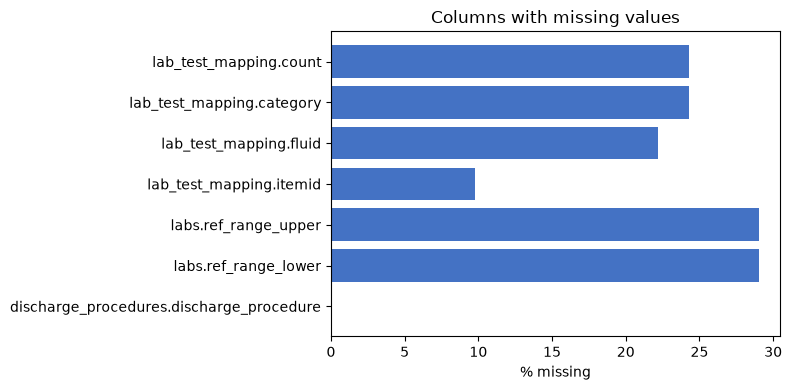

In [11]:
bundle = dict(cleaned)
bundle["lab_test_mapping"] = pd.read_csv(E.EXT_CDM_DIR / "lab_test_mapping.csv")
rows = []
for name, df in bundle.items():
    n = len(df)
    for col in df.columns:
        n_missing = int(df[col].isna().sum())
        rows.append({
            "table": name,
            "column": col,
            "n_missing": n_missing,
            "pct_missing": round(n_missing / n * 100, 4),
            "action": E.MISSING_RULES.get((name, col), "none" if n_missing == 0 else "review"),
        })
miss_df = pd.DataFrame(rows)
display(miss_df)

only = miss_df[miss_df["n_missing"] > 0]
fig, ax = plt.subplots()
ax.barh(only["table"].str.replace("laboratory_tests", "labs") + "." + only["column"], only["pct_missing"], color="#4472c4")
ax.set_xlabel("% missing")
ax.set_title("Columns with missing values")
fig.tight_layout()
fig.savefig(FIG / "cleaning_missing.png", dpi=150, bbox_inches="tight")
plt.show()


### 2.3 Preprocessing — formatting

Text columns are cast to string, trimmed, and collapsed to single spaces, including line breaks inside radiology reports. Empty discharge-procedure rows are dropped. `hadm_id` stays an integer. The files are UTF-8; pandas read every table without an encoding error.

The before/after window is centered on the first character that changed, so a collapsed space or a removed line break is visible.


In [ ]:
def _norm(series):
    return series.astype(str).str.strip().str.replace(r"\s+", " ", regex=True)

def _window(before, after, pad=28):
    """Show the stretch of text where the formatting actually changed."""
    a, b = str(before), str(after)
    limit = min(len(a), len(b))
    i = next((k for k in range(limit) if a[k] != b[k]), 0)
    lo = max(0, i - 12)
    return a[lo:lo + pad], b[lo:lo + pad]

format_rows = []
examples = []
for name, col in E.TEXT_COLUMNS.items():
    raw = cleaned[name][col]
    formatted = _norm(raw)
    changed = raw.fillna("").astype(str) != formatted
    format_rows.append({
        "table": name,
        "column": col,
        "rows": len(raw),
        "rows_rewritten": int(changed.sum()),
        "empty_after_strip": int((formatted.str.strip() == "").sum()),
    })
    if changed.any():
        i = changed[changed].index[0]
        before, after = _window(raw.loc[i], formatted.loc[i])
        examples.append({"table": name, "before": before, "after": after})

proc_before = len(cleaned["discharge_procedures"])
proc_empty = int(cleaned["discharge_procedures"]["discharge_procedure"].isna().sum())
print(f"hadm_id dtype: {cleaned['history_of_present_illness']['hadm_id'].dtype}")
print(f"discharge_procedures: {proc_before:,} rows after dedup, {proc_empty} empty row dropped in the next step")
display(pd.DataFrame(format_rows))
display(pd.DataFrame(examples))


### 2.4 Preprocessing — transformations

Each rule has a reason. Lab strings such as `5.5 units` or `>100 mg/dL` become a number, a unit, and a `<` / `>` qualifier. The number is compared with that row's own reference range and marked low, normal, high, or unknown. Results that are words (`NEG`, `Clear`) stay unknown. They are not forced into a number.


In [ ]:
display(pd.DataFrame(E.TRANSFORM_LOG, columns=["table", "input", "operation", "output", "why"]))

transformed = E.transform_tables(cleaned)
labs = transformed["laboratory_tests"]
proc_after = len(transformed["discharge_procedures"])

accounting = pd.DataFrame([
    ["laboratory_tests", len(tables["laboratory_tests"]), len(cleaned["laboratory_tests"]), len(labs), "duplicates only; parse adds columns, drops no lab rows"],
    ["discharge_procedures", len(tables["discharge_procedures"]), len(cleaned["discharge_procedures"]), proc_after, "duplicates, then drop rows with an empty procedure"],
    ["icd_procedures", len(tables["icd_procedures"]), len(cleaned["icd_procedures"]), len(transformed["icd_procedures"]), "exact duplicate rows"],
    ["icd_diagnosis", len(tables["icd_diagnosis"]), len(cleaned["icd_diagnosis"]), len(transformed["icd_diagnosis"]), "exact duplicate rows"],
], columns=["table", "raw_rows", "after_dedup", "after_transform", "what_changed"])
display(accounting)

print(
    f"Labs: {labs['value_is_numeric'].mean()*100:.1f}% numeric, "
    f"{int(labs['qualifier'].notna().sum()):,} with a < or > qualifier, "
    f"{int(labs['label'].isna().sum())} unlabeled after the name join"
)
show_cols = ["label", "valuestr", "value", "unit", "qualifier", "ref_range_lower", "ref_range_upper", "flag"]
parsed = labs[labs["value_is_numeric"]].head(4)
not_numeric = labs[~labs["value_is_numeric"]].head(3)
display(pd.concat([parsed, not_numeric])[show_cols].reset_index(drop=True))
display(labs["flag"].value_counts().rename_axis("flag").reset_index(name="rows"))


### 2.5 Outliers

Extreme values are counted and kept. A very long history, or a lab far outside its reference range, is a real clinical row. Dropping it would hide the cases the checker is meant to see.


In [14]:
words = transformed["history_of_present_illness"]["word_count"]
hi = float(words.quantile(0.99))
outlier_summary = pd.DataFrame([
    ["HPI longer than the 99th percentile", int((words > hi).sum()), f"threshold {hi:.0f} words", "kept"],
    ["Lab rows flagged low or high", int(labs["flag"].isin(["low", "high"]).sum()), "outside the row's own reference range", "kept"],
    ["Lab rows flagged unknown", int((labs["flag"] == "unknown").sum()), "no numeric value or no reference range", "kept"],
], columns=["check", "rows", "rule", "action"])
outlier_summary


,check,rows,rule,action
0,HPI longer than the 99th percentile,24,threshold 621 words,kept
1,Lab rows flagged low or high,27035,outside the row's own reference range,kept
2,Lab rows flagged unknown,42933,no numeric value or no reference range,kept


### 2.6 Validation

The same checks are run twice. They pass on the cleaned tables. They fail on a copy that was broken on purpose: duplicate case ids, empty text, a dropped `hadm_id` column, an unknown case id, and missing radiology cases.


In [15]:
good = E.validate_tables(cleaned, ids)
bad = E.validate_tables(E.corrupt(cleaned), ids)
print("Cleaned tables:", "PASS" if not good else "FAIL")
for problem in good:
    print(" -", problem)
print(f"Corrupted copy: FAIL, {len(bad)} problems caught" if bad else "Corrupted copy: PASS (unexpected)")
pd.DataFrame({"problem_caught_on_corrupted_copy": bad})


Cleaned tables: PASS
Corrupted copy: FAIL, 5 problems caught


,problem_caught_on_corrupted_copy
0,laboratory_tests: missing columns ['hadm_id']
1,history_of_present_illness: 3 duplicated hadm_id in a one-row-per-case table
2,microbiology: 1 hadm_id not in pathology_ids.json
3,radiology_reports: 28 cases have no rows
4,history_of_present_illness.hpi: 10 empty values


## 3. Exploratory data analysis

The table is the summary. Each plot is followed by the finding: the number, and what it changes in this project. No note text is plotted.


In [16]:
master = transformed["cases_master"]
stats = pd.DataFrame({
    "hpi_words": master["hpi_words"].describe(),
    "lab_rows_per_case": master["n_laboratory_tests"].describe(),
    "radiology_reports_per_case": master["n_radiology_reports"].describe(),
    "icd_diagnoses_per_case": master["n_icd_diagnosis"].describe(),
}).round(1).T[["mean", "std", "min", "50%", "max"]]
stats.to_csv(ROOT / "results" / "eda_summary.csv")
stats


,mean,std,min,50%,max
hpi_words,172.1,124.0,14.0,131.0,1450.0
lab_rows_per_case,57.8,16.3,15.0,56.0,161.0
radiology_reports_per_case,2.5,3.4,1.0,2.0,89.0
icd_diagnoses_per_case,7.2,6.4,1.0,5.0,39.0


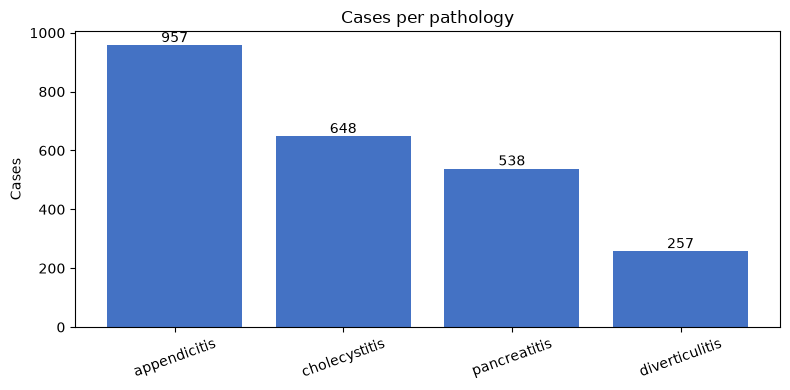

In [17]:
counts = master["pathology"].value_counts()
fig, ax = plt.subplots()
bars = ax.bar(counts.index, counts.values, color="#4472c4")
ax.bar_label(bars)
ax.set_title("Cases per pathology")
ax.set_ylabel("Cases")
ax.tick_params(axis="x", rotation=20)
fig.tight_layout()
fig.savefig(FIG / "eda_class_balance.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** Appendicitis has 957 cases and diverticulitis has 257, about 3.7 times as many. One overall accuracy number would mostly reflect appendicitis. The split is stratified, and results should be reported for each pathology.


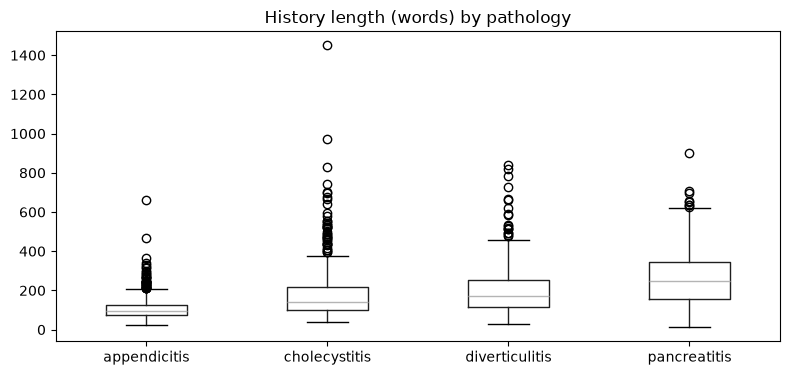

In [18]:
fig, ax = plt.subplots()
master.boxplot(column="hpi_words", by="pathology", ax=ax, grid=False)
ax.set_title("History length (words) by pathology")
ax.set_xlabel("")
plt.suptitle("")
fig.tight_layout()
fig.savefig(FIG / "eda_hpi_length.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** The median history is 131 words and the longest is 1,450. The median is 95 words for appendicitis and 248 for pancreatitis. The model does not see the same amount of text in every class.


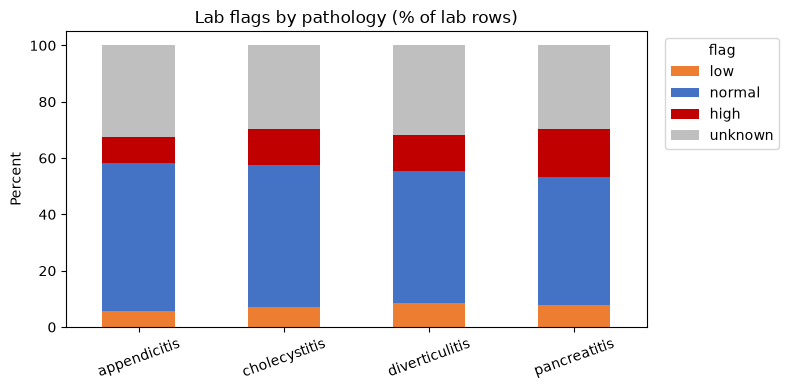

In [19]:
share = labs.merge(master[["hadm_id", "pathology"]], on="hadm_id")
share = share.groupby(["pathology", "flag"]).size().unstack(fill_value=0)
pct = share.div(share.sum(axis=1), axis=0) * 100
fig, ax = plt.subplots()
pct[["low", "normal", "high", "unknown"]].plot.bar(
    stacked=True, color=["#ed7d31", "#4472c4", "#c00000", "#bfbfbf"], ax=ax
)
ax.set_title("Lab flags by pathology (% of lab rows)")
ax.set_xlabel("")
ax.set_ylabel("Percent")
ax.tick_params(axis="x", rotation=20)
ax.legend(title="flag", bbox_to_anchor=(1.02, 1), loc="upper left")
fig.tight_layout()
fig.savefig(FIG / "eda_lab_flags.png", dpi=150, bbox_inches="tight")
plt.show()

**Finding.** 30.9% of lab rows have no usable number or reference range, so they stay unknown rather than being imputed. Of the rows that can be flagged, 28.2% are abnormal: pancreatitis 35%, diverticulitis 31%, cholecystitis 29%, appendicitis 22%.


In [ ]:
num = master[["hpi_words", "n_laboratory_tests", "n_radiology_reports", "n_icd_diagnosis", "n_microbiology"]]
corr = num.corr().round(2)
fig, ax = plt.subplots()
image = ax.imshow(corr, cmap="Blues", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=30, ha="right")
ax.set_yticks(range(len(corr)), corr.columns)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=8)
ax.set_title("Correlation of per-case counts")
fig.colorbar(image, ax=ax, fraction=0.046)
fig.tight_layout()
fig.savefig(FIG / "eda_correlation.png", dpi=150, bbox_inches="tight")
plt.show()


**Finding.** Note length, lab count, radiology count, and diagnosis count are only weakly correlated. None of them stands in for the others. Labs and radiology cover all 2,400 cases. Microbiology covers 77%, so a rule that needs a culture has no input on about one case in four.


### Important findings

Each row is computed from this run. The number is the evidence. The last column is what the project should do about it.


In [21]:
abn = labs[labs["flag"] != "unknown"].assign(abnormal=lambda d: d["flag"].isin(["low", "high"]))
abn_by_path = (
    abn.merge(master[["hadm_id", "pathology"]], on="hadm_id")
    .groupby("pathology")["abnormal"].mean()
    .mul(100)
    .round(0)
)
words_by_path = master.groupby("pathology")["hpi_words"].median().round(0)
micro_cov = master["n_microbiology"].gt(0).mean() * 100
unknown_pct = (labs["flag"] == "unknown").mean() * 100
by_class = ", ".join(f"{k} {v:.0f}%" for k, v in abn_by_path.sort_values(ascending=False).items())
length_by_class = ", ".join(f"{k} {int(v)}" for k, v in words_by_path.items())

findings = pd.DataFrame([
    [
        "Class imbalance",
        f"{counts.idxmax()} {int(counts.max())} vs {counts.idxmin()} {int(counts.min())} ({counts.max()/counts.min():.1f}x)",
        "Stratify the split and report results per class. One accuracy number mostly reflects appendicitis.",
    ],
    [
        "Labs that cannot be flagged",
        f"{unknown_pct:.1f}% of lab rows",
        "Leave them as unknown. Do not impute a reference range the source did not provide.",
    ],
    [
        "Abnormal results among labs that can be flagged",
        f"{abn['abnormal'].mean()*100:.1f}% overall ({by_class})",
        "A high/low rule will fire often, and more often in pancreatitis than in appendicitis.",
    ],
    [
        "History length",
        f"median {int(master['hpi_words'].median())} words, max {int(master['hpi_words'].max())}; median by class: {length_by_class}",
        "Pancreatitis notes are much longer than appendicitis notes. Input size is part of the class difference.",
    ],
    [
        "Coverage gap",
        f"labs and radiology 100% of {len(master)} cases; microbiology {micro_cov:.0f}%",
        "A rule that needs a culture has no input on about one case in four.",
    ],
    [
        "Duplicates were narrow",
        f"{int(dup_report['duplicate_rows'].sum())} rows, only in ICD and procedure tables",
        "The note tables were already one row per case. Cleaning did not drop any admission.",
    ],
    [
        "Scope of the benchmark",
        "4 abdominal pathologies",
        "A checker tuned only on these cases does not cover other discharge settings.",
    ],
], columns=["finding", "evidence", "why it matters"])
findings


,finding,evidence,why it matters
0,Class imbalance,appendicitis 957 vs diverticulitis 257 (3.7x),Stratify the split and report results per class. One accuracy number mostly reflects a...
1,Labs that cannot be flagged,30.9% of lab rows,Leave them as unknown. Do not impute a reference range the source did not provide.
2,Abnormal results among labs that can be flagged,"28.2% overall (pancreatitis 35%, diverticulitis 31%, cholecystitis 29%, appendicitis 22%)","A high/low rule will fire often, and more often in pancreatitis than in appendicitis."
3,History length,"median 131 words, max 1450; median by class: appendicitis 95, cholecystitis 142, diver...",Pancreatitis notes are much longer than appendicitis notes. Input size is part of the ...
4,Coverage gap,labs and radiology 100% of 2400 cases; microbiology 77%,A rule that needs a culture has no input on about one case in four.
5,Duplicates were narrow,"75 rows, only in ICD and procedure tables",The note tables were already one row per case. Cleaning did not drop any admission.
6,Scope of the benchmark,4 abdominal pathologies,A checker tuned only on these cases does not cover other discharge settings.


## 4. Splits

100 cases are held out for the test set named in the abstract. Of the rest, 20% is validation. The split is stratified by pathology (seed 298) and **grouped by patient**: every admission of one patient goes to the same split.

The first version (v1) split by admission and let 5 patients cross splits. It stays in the repository as the record of that check (`docs/split_leakage_check.md`). Only case IDs are saved.

In [21]:
subject_of = E.subject_map()

v1 = S.make_splits(cases)
print("v1 (split by admission): patients present in more than one split ->", S.patient_overlap(v1, subject_of))

made = S.make_grouped_splits(cases, subject_of)
summary = S.split_summary(made, cases)
problems = S.leakage_check(made, cases) + S.patient_leakage_check(made, subject_of)
path = S.save_splits(made, ROOT / "data" / "splits", filename="ext_cdm_splits_v2.json", grouped_by="subject_id")
print("v2 (grouped by patient):", "PASS - no shared IDs, no patient in two splits, all 2,400 cases assigned" if not problems else problems)
print("Same IDs if the split is rebuilt with seed 298:", S.make_grouped_splits(cases, subject_of) == made)
print("Saved:", path.relative_to(ROOT))
summary

v1 (split by admission): patients present in more than one split -> {'train+val': 4, 'train+test': 1, 'val+test': 0}
v2 (grouped by patient): PASS - no shared IDs, no patient in two splits, all 2,400 cases assigned


Same IDs if the split is rebuilt with seed 298: True
Saved: data/splits/ext_cdm_splits_v2.json


,train,val,test
pathology,,,
appendicitis,733,184,40
cholecystitis,497,124,27
pancreatitis,413,103,22
diverticulitis,197,49,11
total,1840,460,100


## What this run covers

- **Extraction:** both sources, the licence, the collection steps, the Ext-CDM checksum, the admissions link check, and a sample of every table.
- **Cleaning:** duplicate counts, missing-value rules, text formatting with a before/after row, lab parsing, outliers kept on purpose, and checks that fail when the tables are corrupted.
- **EDA:** summary statistics, class imbalance, history-length distribution, lab-flag mix, correlation of per-case counts, and the coverage gaps those plots show.
- **Splits:** a stratified train/validation/test split grouped by patient, with admission-level and patient-level leakage checks, and the v1 problem it fixes.
